**Before starting this practical session**:

1. **Change the runtime type on Google Colab**: `Runtime > Change runtime type > T4 GPU`
2. **Install the packages below**:

In [1]:
! pip install lightning torchmetrics torchinfo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 17.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 30.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 32.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [lightning]


# Introduction to PyTorch and PyTorch-Lightning

There are many libraries and programming languages for practicing deep learning. Throughout these practical sessions, we will use the Python programming language, along with the [PyTorch](https://pytorch.org) package and other packages from this ecosystem.

The goal of this Jupyter notebook is to provide you with the basics for getting started with the PyTorch library. By the end of this notebook, you should be able to:
* **work with tensors**,
* **specify how to access data to train and evaluate a model**,
* **build an artificial neural network**, and
* **train and evaluate your model**.

The content of this notebook is based on the [tutorials](https://pytorch.org/tutorials/) available on the PyTorch website.

## Tensors

PyTorch tensors follow a specialized data structure and are very similar to NumPy arrays. Tensors are used to model the inputs and outputs of a model, as well as the model's parameters.

PyTorch tensors are similar to NumPy arrays, with one major difference being that tensors can run on graphics cards (*graphics processing units* or GPUs).
In fact, PyTorch tensors and NumPy arrays can even share the same memory space, removing the need to copy data.
Tensors are also optimized for [automatic differentiation](https://pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html).
If you are familiar with NumPy arrays, you will quickly become familiar with PyTorch tensors as well.

In [2]:
import torch
import numpy as np

### Initializing a tensor

In [3]:
# From "Python" data (e.g., lists of integers here)
data = [[1, 2], [3, 4]]
x_data = torch.tensor(data)
x_data

tensor([[1, 2],
        [3, 4]])

In [4]:
# From a NumPy array
np_array = np.array(data)
x_np = torch.from_numpy(np_array)
x_np

tensor([[1, 2],
        [3, 4]])

In [5]:
# From another tensor
x_ones = torch.ones_like(x_data)
x_ones

tensor([[1, 1],
        [1, 1]])

In [6]:
# With random or constant values
shape = (2, 3)
rand_tensor = torch.rand(shape)
ones_tensor = torch.ones(shape)
zeros_tensor = torch.zeros(shape)

print(f"Random tensor:\n{rand_tensor} \n")
print(f"Tensor full of ones:\n{ones_tensor} \n")
print(f"Tensor full of zeros:\n{zeros_tensor}")

Random tensor:
tensor([[0.0050, 0.9128, 0.8556],
        [0.3948, 0.8101, 0.0132]]) 

Tensor full of ones:
tensor([[1., 1., 1.],
        [1., 1., 1.]]) 

Tensor full of zeros:
tensor([[0., 0., 0.],
        [0., 0., 0.]])


### Attributes of a tensor

The attributes of a tensor describe its characteristics such as its shape, its data type, or the type of device it is stored on.

In [7]:
tensor = torch.rand(3, 4)

print(f"Shape of the tensor: {tensor.shape}")
print(f"Data type of the tensor: {tensor.dtype}")
print(f"Device on which the tensor is stored: {tensor.device}")

Shape of the tensor: torch.Size([3, 4])
Data type of the tensor: torch.float32
Device on which the tensor is stored: cpu


**Note that the default data type of a tensor is `float32`, whereas the default type of a NumPy array is `float64`. PyTorch requires that all tensors have the same data type in order to perform operations between them.**

You can change the data type of a tensor with the `to()` method:

In [8]:
x_np.to(dtype=torch.float32)

tensor([[1., 2.],
        [3., 4.]])

### Operations on tensors

Many operations, such as arithmetic, linear algebra, and matrix operations (such as transposing, indexing, or slicing), are detailed in the [documentation](https://pytorch.org/docs/stable/torch.html).

Each of these operations can be run on a GPU (generally faster than on a CPU).
On Google Colab, changing the runtime type (CPU or GPU) restarts the kernel, meaning all previously executed code must be run again.
**This is why the first instruction of this notebook, as well as of all other notebooks, is to change the runtime type and choose GPU instead of CPU.**
TPUs (for [*Tensor Processing Units*](https://en.wikipedia.org/wiki/Tensor_Processing_Unit)) are other hardware accelerators developed by Google, but we will not use them.

By default, tensors are created on the CPU. Tensors must be explicitly moved to the GPU using the `to()` method (after checking GPU availability). Keep in mind that copying large tensors to other devices can be costly both in terms of time and memory.

In [9]:
# Example: move a tensor to the GPU if it is available
if torch.cuda.is_available():
    tensor = tensor.to("cuda")

In [10]:
# Indexing and slicing operations (similar to the ones available for NumPy arrays)
tensor = torch.ones(4, 4)
print(f"First row: {tensor[0]}")
print(f"First column: {tensor[:, 0]}")
print(f"Last column: {tensor[..., -1]}")
tensor[:, 1] = 0  # Set all the values in the second column to zero
print(tensor)

First row: tensor([1., 1., 1., 1.])
First column: tensor([1., 1., 1., 1.])
Last column: tensor([1., 1., 1., 1.])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


In [11]:
# Concatenate tensors (along a specific dimension)
t1 = torch.cat([tensor, tensor, tensor], dim=1)
print(t1)

tensor([[1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.],
        [1., 0., 1., 1., 1., 0., 1., 1., 1., 0., 1., 1.]])


In [12]:
# Mathematical operations

## Three ways to perform matrix multiplication
y1 = tensor @ tensor.T

y2 = tensor.matmul(tensor.T)

y3 = torch.rand_like(y1)
torch.matmul(tensor, tensor.T, out=y3)

## Three ways to perform the Hadamard product (element-wise multiplication)
z1 = tensor * tensor

z2 = tensor.mul(tensor)

z3 = torch.rand_like(tensor)
torch.mul(tensor, tensor, out=z3)

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])

In [13]:
# Tensor with a single element and transforming it into a native Python type
agg = tensor.sum()
print(agg, type(agg))

agg_item = agg.item()
print(agg_item, type(agg_item))

tensor(12.) <class 'torch.Tensor'>
12.0 <class 'float'>


## Dataset and dataloaders

Access to data is an essential element for training models. PyTorch provides two tools that make it easier to access data: [`torch.utils.data.Dataset()`](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) and [`torch.utils.data.DataLoader()`](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader). These tools allow you to work both with commonly used public datasets and with your own dataset.

The [`torch.utils.data.Dataset()`](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) class defines a dataset, in particular its size (i.e., its number of observations) and how to access any observation.

The [`torch.utils.data.DataLoader()`](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) class defines, for a dataset, a dataloader, in particular how to access several observations at once, whether or not to shuffle the order of observations, etc. The dataloader is the tool used for training and evaluating models.

### Loading a commonly used dataset

Some commonly used datasets can be easily downloaded thanks to tools provided in other libraries of the PyTorch ecosystem such as [TorchVision](https://pytorch.org/vision/stable/index.html), [TorchText](https://pytorch.org/text/stable/index.html), and [TorchAudio](https://pytorch.org/audio/stable/index.html).

In this tutorial, we will download and use the [Fashion MNIST](https://en.wikipedia.org/wiki/Fashion_MNIST) dataset, consisting of fashion images of size `28 x 28`. The training set is made up of 60,000 images, while the test set is made up of 10,000 images (we will use it as a validation set). The dataset is available through the [`torchvision.datasets.FashionMNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.FashionMNIST.html#torchvision.datasets.FashionMNIST) class.

In [29]:
from torchvision import datasets
from torchvision.transforms import ToTensor


dataset_train = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)

dataset_val = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor()
)

### Iterating over and visualizing the dataset

An instance of the `Dataset` class is indexable, like a Python list: `dataset_train[index]`.

Since our observations are images, we will visualize some observations using the `matplotlib` library.

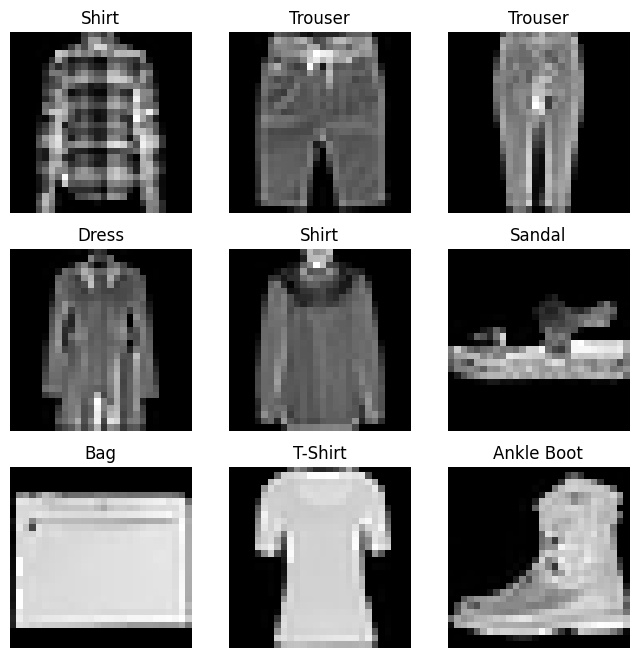

In [30]:
import matplotlib.pyplot as plt

# Define the mapping between the labels in the data sets (digits between 0 and 9) and the true labels
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}


# Show 9 samples randomly drawn from the training set
figure = plt.figure(figsize=(8, 8))
rows, cols = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(dataset_train), size=(1,)).item()
    img, label = dataset_train[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

### Working with your own dataset

#### General case

In practice, you will not be working on a commonly used public dataset but on your own dataset. It is nevertheless possible to use some of the available tools, provided certain constraints are respected.

If you are working on your own dataset, you will need to define a class inheriting from the [`torch.utils.data.Dataset()`](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) class, which defines the following three methods:
* `__len__()`: this method returns the number of observations in the dataset.
* `__getitem__()`: this method loads and returns the n-th observation of the dataset (where n is an argument of the method)
* `__init__()`: this method defines all the information needed to implement the other two methods.

You will find [here](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html#creating-a-custom-dataset-for-your-files) an example taken from the PyTorch documentation for a dataset consisting of images. This example is copied below. **This is only an example; it should not be copy-pasted without understanding it.**


```python
import os
import pandas as pd
from torchvision.io import read_image
from torch.utils.data import Dataset


class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = img_dir
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
        image = read_image(img_path)
        label = self.img_labels.iloc[idx, 1]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label
```

#### Case with tensors already loaded

When your data is already loaded into tensors, a convenient class is [`torch.utils.data.TensorDataset()`](https://pytorch.org/docs/stable/data.html#torch.utils.data.TensorDataset).
The first dimension of each tensor must be the observation dimension.
Then, you simply need to provide the tensors as arguments to the constructor of this class: each observation will be retrieved by indexing the tensors along the first dimension.

### Preparing data for training with the DataLoader

The `Dataset` class allows you to retrieve any observation from a dataset. When training a model, we generally want to access several observations at once (in mini-batches) and shuffle the dataset at each epoch to reduce overfitting.

To do this, we use the [`torch.utils.data.DataLoader()`](https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader) class. Its first, required, argument is the dataset, i.e., the instance of the [`torch.utils.data.Dataset()`](https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset) class.
The other important, optional, arguments are the batch size (`batch_size`) and whether or not to shuffle the dataset (`shuffle`). Shuffling the dataset during training can be useful to avoid overfitting, but it is unnecessary for evaluation.

In [39]:
from torch.utils.data import DataLoader

dataloader_train = DataLoader(dataset_train, batch_size=100, shuffle=True)
dataloader_val = DataLoader(dataset_val, batch_size=100)

### Iterating through the `DataLoader`

We have loaded the dataset and can iterate through it. Using the native [`iter()`](https://docs.python.org/3/library/functions.html#iter) and [`next()`](https://docs.python.org/3/library/functions.html#next) functions, we can access the next batch of observations:

Shape of the tensor consisting of the images in this batch: torch.Size([100, 1, 28, 28])
Shape of the tensor consisting of the labels in this batch: torch.Size([100])


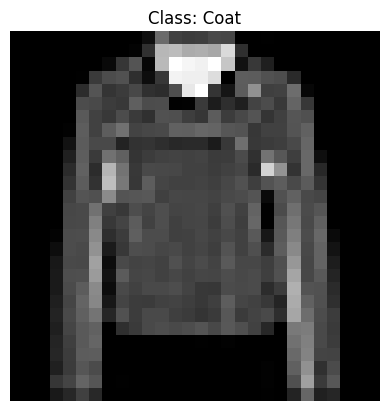

In [40]:
# Get the next mini-batch of samples
train_features, train_labels = next(iter(dataloader_train))
print(f"Shape of the tensor consisting of the images in this batch: {train_features.size()}")
print(f"Shape of the tensor consisting of the labels in this batch: {train_labels.size()}")

# Display the image and the label of the first sample in the mini-batch
img = train_features[0].squeeze()
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.title(f"Class: {labels_map[label.item()]}")
plt.axis("off")
plt.show()

## Building, training, and evaluating an artificial neural network with PyTorch

### Building a neural network with PyTorch

To build a neural network with PyTorch, there are a few simple rules to follow:

* You need to define a class inheriting from the [`torch.nn.Module()`](https://pytorch.org/docs/stable/generated/torch.nn.Module.html) class.
* The class must contain at least the following two methods:

    + The constructor `__init__()`, where the parent class constructor is always called and where all layers are initialized (and where activation functions can also be defined).
    + The `forward()` method, which defines the forward pass, i.e., how to go from the input to the output.

All the elements needed to define a neural network are found in the [`torch.nn`](https://pytorch.org/docs/stable/nn.html) module, in particular all the layers and activation functions.

In the example below, we define a neural network with the following sequential architecture:
1. a flatten layer, to transform an image into a vector,
2. a first linear layer with $28 \times 28 = 784$ inputs and $512$ outputs,
3. the ReLU activation function,
4. a second linear layer with $512$ inputs and $512$ outputs,
5. the ReLU activation function,
6. a third linear layer with $512$ inputs and $10$ outputs.

You will notice that we do not use the $\text{softmax}$ activation function to transform the final vector of 10 real numbers into a vector of probabilities. Indeed, the $\text{softmax}$ function uses the exponential function, and the loss function we will use, cross-entropy, uses the logarithm of the probabilities. It is therefore simpler (and also more numerically stable) to work directly with **logits** rather than probabilities.

In [41]:
class NeuralNetworkPyTorch(torch.nn.Module):
    def __init__(self):
        # We always call the constructor of the parent class
        super().__init__()

        # This layer flattens a n-dimensional tensor into a 1-dimensional tensor
        self.flatten = torch.nn.Flatten()

        # First linear layer
        self.linear1 = torch.nn.Linear(28 * 28, 512)

        # First activation function
        self.relu1 = torch.nn.ReLU()

        # Second linear layer
        self.linear2 = torch.nn.Linear(512, 512)

        # Second activation function. This is not necessary but we can do it for better readability
        self.relu2 = torch.nn.ReLU()

        # Third linear layer
        self.linear3 = torch.nn.Linear(512, 10)

    def forward(self, x):
        # We define how to map the input (x) to the predicted output (y) returned by this method
        y = self.flatten(x)
        y = self.linear1(y)
        y = self.relu1(y)
        y = self.linear2(y)
        y = self.relu2(y)
        y = self.linear3(y)
        return y

An obvious drawback of this approach is that we are forced to call each layer and each activation function one by one. Not only is this tedious even for such a small architecture, but it also carries a non-negligible risk of error, especially with a larger network. Fortunately, when part of the architecture is sequential, we can use the [`torch.nn.Sequential()`](https://pytorch.org/docs/stable/generated/torch.nn.Sequential.html) class to specify the list of layers and activation functions in the sequence. When this object is then called, the sequence is traversed in the order provided and we simply retrieve the output of the sequence.

The code below illustrates the simplification of the `forward()` method using this tool.

In [34]:
class NeuralNetworkPyTorchSimpler(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.sequential = torch.nn.Sequential(
            torch.nn.Flatten(),
            torch.nn.Linear(28 * 28, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, 10),
        )

    def forward(self, x):
        return self.sequential(x)

We can visualize the architecture of our neural network using the [`torchinfo.summary()`](https://github.com/TylerYep/torchinfo?tab=readme-ov-file#documentation) function. By also providing the input size (including the batch dimension), we can easily visualize the output size of each layer.

In [35]:
from torchinfo import summary

model = NeuralNetworkPyTorchSimpler()
summary(model, input_size=(64, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
NeuralNetworkPyTorchSimpler              [64, 10]                  --
├─Sequential: 1-1                        [64, 10]                  --
│    └─Flatten: 2-1                      [64, 784]                 --
│    └─Linear: 2-2                       [64, 512]                 401,920
│    └─ReLU: 2-3                         [64, 512]                 --
│    └─Linear: 2-4                       [64, 512]                 262,656
│    └─ReLU: 2-5                         [64, 512]                 --
│    └─Linear: 2-6                       [64, 10]                  5,130
Total params: 669,706
Trainable params: 669,706
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 42.86
Input size (MB): 0.20
Forward/backward pass size (MB): 0.53
Params size (MB): 2.68
Estimated Total Size (MB): 3.41

### Device to work on

By default, all defined tensors are placed on **central processing units** (CPUs). However, there are other units, such as **graphics processing units** (GPUs), which are much faster for performing certain mathematical operations, in particular those needed in deep learning such as matrix computation.

**In short, if you use GPUs instead of CPUs, the execution of forward and backward passes will, *in general*, be much faster: training and inference will therefore, *in general*, be much faster.**

On Google Colab, you can change the resources you have access to by going to `Runtime > Change runtime type` and clicking on `T4 GPU` instead of `CPU`.
Changing the hardware accelerator restarts your kernel (meaning you lose all the variables you had defined and need to re-run the code from the beginning).
**It is therefore important to choose the hardware accelerator type at the very beginning so as not to lose work already done.**

**CUDA** (for *Compute Unified Device Architecture*) is a technology that allows computations to be run on a GPU instead of a CPU.
This is the term used in the PyTorch library.
To find out (or check) whether you have access to a GPU, we use the [`torch.cuda.is_available()`](https://pytorch.org/docs/stable/generated/torch.cuda.is_available.html) function:

In [23]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)
print(f"Using {device} device")

Using cuda device


**Everything needs to be placed on the same device**. For example, if you want to use a GPU, then the model must be placed on the GPU, but also each batch of observations must be placed on the GPU during training and inference. We therefore start by placing the model on the GPU.

In [24]:
model = model.to(device)

**To perform the forward pass of the model, we do not directly use the `forward()` method but instead call the model directly** (calling the model performs additional operations).
For example, with the code below:
1. We define an image where all the pixels are random and place it on the correct device.
2. We perform the forward pass to obtain the logits.
3. We obtain the index of the predicted class, which corresponds to the index of the maximum logit.
4. We display the name of the predicted class.

In [25]:
x = torch.rand(1, 28, 28, device=device)
logits = model(x)
y_pred = logits.argmax(1)
print(f"Predicted class = {labels_map[y_pred.item()]}")
del x, logits, y_pred

Predicted class = Trouser


### Training and evaluation

Using only the PyTorch package, you need to write the code for training and evaluating a model yourself. However, we have already defined almost all the elements needed for training the model. We still need to define the loss function, the optimization algorithm, as well as certain hyperparameters such as the number of epochs.

The [`torch.nn`](https://pytorch.org/docs/stable/nn.html) module provides the various [loss functions](https://pytorch.org/docs/stable/nn.html#loss-functions) already implemented in PyTorch. For optimization algorithms, you need to use the [`torch.optim`](https://pytorch.org/docs/stable/optim.html) module.

* **Loss function**: since we are working on a multi-class classification problem, we will use *cross-entropy*: [`torch.nn.CrossEntropyLoss()`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html).
* **Optimization algorithm**: we will use the *Adam* algorithm, which is generally a good default algorithm: [`torch.optim.Adam()`](https://pytorch.org/docs/stable/generated/torch.optim.Adam.html).

Note that we have already defined some hyperparameters without necessarily realizing it, for example **the batch size** (`batch_size`) on the training set through the *dataloader* for this set. We are also using the default values of the hyperparameters for the Adam algorithm here, but they could be changed.

Using a fixed number of epochs, the general procedure for training a model is as follows:
```
For each epoch
    For each batch of the training set
        [Optional] Place the data on the correct device (GPU)
        Perform the forward pass and compute the loss function
        Perform the backward pass (compute the gradients)
        Perform an optimization step (update the model's trainable parameters)
```

Optimization takes place in three steps of the nested loop:
* The `zero_grad()` method of the optimization algorithm resets the gradients of the model's parameters. By default, gradients accumulate across iterations. To avoid this accumulation, they must be explicitly reset to zero at the beginning of each iteration.
* The backward pass is performed using the `backward()` method of the loss function. Here, PyTorch computes the gradient of the loss function with respect to each trainable parameter.
* The update of the model's trainable parameters is performed using the `step()` method of the optimization algorithm, based on the gradients computed during the backward pass.

The code below defines three functions:
* The `train_loop()` function corresponds to training the model for one epoch on the training set.
* The `eval_loop()` function corresponds to evaluating a model on a dataset.
* The `train()` function performs the complete training of the model.

In [42]:
def train_loop(dataloader, model, loss_function, optimizer, device, verbose=False):
    # Set the model to training mode.
    # It is a best practice because some layers behave differently in training and evaluation modes.
    # Here, it has no impact since all the layers that are used behave the same way in both modes.
    model.train()

    loss_mean, accuracy_mean = 0.0, 0.0

    # For each batch
    for batch, (x, y) in enumerate(dataloader):

        # Reset the gradients to zeros
        optimizer.zero_grad()

        # Place the batch of samples on the device
        x = x.to(device)
        y = y.to(device)

        # Perform the forward pass, evaluate the loss function and compute the accuracy
        pred = model(x)
        loss = loss_function(pred, y)
        accuracy = (pred.argmax(1) == y).to(torch.float).mean().item()

        loss_mean += loss.item()
        accuracy_mean += accuracy

        # Perform the backward pass and update the trainable parameters of the model
        loss.backward()
        optimizer.step()

        # Display the value of the loss function from time to time
        if verbose and (batch % max(1, len(dataloader) // 10) == 0):
            loss = loss.item()
            print(
                f"Loss function = {loss: >7f} | "
                f"Accuracy = {accuracy:06.2%} "
                f"[{batch + 1: >3d} / {len(dataloader): >3d}]"
            )

    loss_mean /= len(dataloader)
    accuracy_mean /= len(dataloader)

    return loss_mean, accuracy_mean


def eval_loop(dataloader, model, loss_function, device):

    # Set the model to evaluation mode.
    # It is a best practice because some layers behave differently in training and inference modes.
    # Here, it has no impact since all the layers that are used behave the same way in both modes.
    model.eval()

    # Define the necessary variables to evaluate the model
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    loss, correct = 0.0, 0.0

    # Evaluating a model in a `torch.no_grad()` context makes sure that no gradient is
    # computed: gradients are not required during evaluation
    with torch.no_grad():

        # For each batch
        for x, y in dataloader:

            # Place the batch of samples on the device
            x = x.to(device)
            y = y.to(device)

            # Perform the forward pass
            pred = model(x)

            # Compute the loss function and the number of correct predictions
            loss += loss_function(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    # Compute the mean loss function and the proportion of correct predictions
    loss /= num_batches
    correct /= size
    return loss, correct


def train(model, dataloader_train, dataloader_val, loss_function, optimizer, n_epochs, device, verbose=True):
    for epoch in range(n_epochs):
        string = f"Epoch {epoch + 1:{len(str(n_epochs))}d} / {n_epochs}"
        print(f"{string}\n{'-' * len(string)}")
        print(" Training set ".center(50 + 2 * len(str(len(dataloader_train))) , '#'))

        # Training loop
        loss_train, accuracy_train = train_loop(
            dataloader_train, model, loss_function, optimizer, device, verbose
        )
        print(f"Loss function = {loss_train: >7f} | Accuracy = {accuracy_train:06.2%} [Mean]")

        # Evaluation loop
        loss_val, accuracy_val = eval_loop(dataloader_val, model, loss_function, device)
        print(" Validation set ".center(50 + 2 * len(str(len(dataloader_train))), '#'))
        print(f"Loss function = {loss_val: >8f} | Accuracy = {(accuracy_val):06.2%}\n")


    print("Training complete!")

We use the `train()` function to train the model for 5 epochs.

In [43]:
train(
    model=model,
    dataloader_train=dataloader_train,
    dataloader_val=dataloader_val,
    loss_function=torch.nn.CrossEntropyLoss(),
    optimizer=torch.optim.Adam(model.parameters()),
    n_epochs=5,
    device=device,
    verbose=True
)

Epoch 1 / 5
-----------
##################### Training set #####################
Loss function = 2.298911 | Accuracy = 04.00% [  1 / 600]
Loss function = 0.507131 | Accuracy = 78.00% [ 61 / 600]
Loss function = 0.506648 | Accuracy = 84.00% [121 / 600]
Loss function = 0.455000 | Accuracy = 84.00% [181 / 600]
Loss function = 0.440144 | Accuracy = 86.00% [241 / 600]
Loss function = 0.367446 | Accuracy = 89.00% [301 / 600]
Loss function = 0.315942 | Accuracy = 86.00% [361 / 600]
Loss function = 0.330113 | Accuracy = 88.00% [421 / 600]
Loss function = 0.332626 | Accuracy = 86.00% [481 / 600]
Loss function = 0.446939 | Accuracy = 84.00% [541 / 600]
Loss function = 0.505986 | Accuracy = 81.63% [Mean]
#################### Validation set ####################
Loss function = 0.404519 | Accuracy = 85.22%

Epoch 2 / 5
-----------
##################### Training set #####################
Loss function = 0.418997 | Accuracy = 82.00% [  1 / 600]
Loss function = 0.405956 | Accuracy = 83.00% [ 61 / 600]

As you can see, training a model with PyTorch requires writing quite a bit of code.
However, we realize that we very often write almost identical pieces of code across different projects, especially when doing classic things.
So we will now look at another library that will allow us to avoid always rewriting the same code each time.

## Building, training, and evaluating an artificial neural network with PyTorch-Lightning

### The basics

One characteristic of PyTorch is that it is a relatively *low-level* library: certain features must be implemented by the user using the available tools. For example, for training, you must write the complete procedure code each time.
In contrast, in libraries like [scikit-learn](https://scikit-learn.org) in Python or [caret](https://cran.r-project.org/web/packages/caret/index.html) in R, you only need to call the `.fit()` method or the `train()` function to perform training.
Some hyperparameters allow you to make modifications to how the model is trained, but you do not have to implement the training yourself.

This *low-level* aspect of PyTorch can be convenient for research work because you generally want access to all the features in order to be able to make modifications if necessary.
It is less convenient when you just want to use a classic version of training.

To do this, we will also use another Python library called [PyTorch Lightning](https://lightning.ai/pytorch-lightning), which will allow us to avoid writing part of the code for training and evaluating the model.

**Everything is done in a single class, defined by the user, which must follow these conventions**:
* The class inherits from the [`lightning.LightningModule()`](https://lightning.ai/docs/pytorch/stable/common/lightning_module.html#lightningmodule) class.
* The constructor calls the parent class constructor.
* **`__init__()` method**: All layers with trainable parameters are initialized in the constructor. To avoid wondering, in case of doubt, whether a layer has trainable parameters or not, it is simpler to initialize all layers and all activation functions in the constructor. All the layers and activation functions we will use are defined in the [`torch.nn`](https://pytorch.org/docs/stable/nn.html) submodule.
* **`forward()` method**: It defines how to perform a forward pass, i.e., how to go from the input to the output of the neural network. However, to perform a forward pass, we never directly call the `forward()` method but instead call the object directly: `self()`.
* **`training_step()` method**: it defines how to perform a training step, i.e., how to go from a batch of observations to the loss function corresponding to that batch of observations.
* **`configure_optimizers()` method**: it defines the optimization algorithm to use. It must be one of the algorithms implemented in the [`torch.optim`](https://pytorch.org/docs/stable/optim.html#algorithms) submodule.

The code below defines a multilayer perceptron with two hidden layers (where images are first transformed into vectors thanks to the `nn.Flatten()` layer), trained with the Adam optimization algorithm using cross-entropy as the loss function:

In [44]:
import lightning as L


class NeuralNetworkLightning(L.LightningModule):  # Always inherit from the lightning.LightningModule class
    def __init__(self):
        """Constructor.

        In the constructor, we always run the constructor of the parent class and we
        instantiate all the elements of our network: the layers, the activation functions, and
        the loss function.
        """
        super().__init__()  # Always run the constructor of the parent class

        # Instantiate the sequence of layers and activation functions
        self.sequential = torch.nn.Sequential(
            torch.nn.Flatten(),
            torch.nn.Linear(28 * 28, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, 10),
        )

        # Instantiate the loss function
        self.loss = torch.nn.CrossEntropyLoss()

    def forward(self, x):
        """Implements the forward pass."""
        return self.sequential(x)

    def training_step(self, batch):
        """Perform a step.

        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : tuple
            A batch of samples.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        x, y = batch  # x corresponds to the inputs, y corresponds to the outputs
        logits = self(x)  # Forward pass outputting the logits
        loss = self.loss(logits, y)  # Evaluation of the loss function
        return loss

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        optimizer = torch.optim.Adam(self.parameters())
        return optimizer

We can still visualize the architecture of our neural network using the [`torchinfo.summary()`](https://github.com/TylerYep/torchinfo?tab=readme-ov-file#documentation) function. By also providing the input size (including the batch dimension), we can easily visualize the output size of each layer.

In [45]:
from torchinfo import summary


model = NeuralNetworkLightning()
summary(model, input_size=(64, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
NeuralNetworkLightning                   [64, 10]                  --
├─Sequential: 1-1                        [64, 10]                  --
│    └─Flatten: 2-1                      [64, 784]                 --
│    └─Linear: 2-2                       [64, 512]                 401,920
│    └─ReLU: 2-3                         [64, 512]                 --
│    └─Linear: 2-4                       [64, 512]                 262,656
│    └─ReLU: 2-5                         [64, 512]                 --
│    └─Linear: 2-6                       [64, 10]                  5,130
Total params: 669,706
Trainable params: 669,706
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 42.86
Input size (MB): 0.20
Forward/backward pass size (MB): 0.53
Params size (MB): 2.68
Estimated Total Size (MB): 3.41

We now need to define an instance of the [`lightning.Trainer()`](https://lightning.ai/docs/pytorch/stable/common/trainer.html) class to define training hyperparameters (such as the maximum number of epochs), then use the `.fit()` method to train our model on a dataset (defined by a *dataloader*).

In [46]:
trainer = L.Trainer(max_epochs=5)
trainer.fit(model=model, train_dataloaders=dataloader_train)

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch

┏━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name       ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ sequential │ Sequential       │  669 K │ train │     0 │
│ 1 │ loss       │ CrossEntropyLoss │      0 │ train │     0 │
└───┴────────────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 669 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 669 K                                                                                                
Total estimated model params size (MB): 2.679                                                                      
Modules in train mode: 8                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
INFO: `Trainer.fit` stopped: `max_epochs=5` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=5` reached.


We can make the following observations:

* We don't need to rewrite all the `for` loops: PyTorch Lightning takes care of that itself.

* The code is better organized: the different steps are defined through specific methods of the class.

* We don't need to specify the type of device (CPU or GPU) we want to work on. This is one of the advantages of PyTorch Lightning: it automatically takes care of placing the model and data on the GPU if one is available. This is the default behavior, and it can of course be changed.

* A `lightning_logs` folder has been created in the current directory. Indeed, PyTorch Lightning saves certain training information by default. Of course, what is saved in these logs can be customized.

* A bar shows the training progress, but no statistics (loss function, accuracy) are displayed to track the *quality* of the training.

We will use advanced PyTorch Lightning settings to fill these gaps. The code savings will therefore be more limited than in this initial basic version, but the results obtained will be more readable and easier to analyze.

### Advanced settings

We have managed to train our model for several epochs, but we have no information on the quality of the training:

* Has the model converged?
* What is the value of the loss function at the end of training?
* What performance can we expect from this trained model?

Fortunately, PyTorch Lightning is very flexible and allows us to customize training, in particular to **display** and **record** relevant training information. We will make the following changes:

* We will add a **validation step**, i.e., at the end of each epoch, we will evaluate our model on a validation set (different from the training set). This allows us to evaluate our model on a dataset independent of the training set.
* We will **display more information during training**, in particular the value of the loss function for certain batches of observations at regular intervals. This allows us to check that the loss function (generally) does decrease during training and to potentially detect overfitting (if the loss function is much lower on the training set than on the validation set).
* We will suppress any warnings displayed by Lightning, which appear between the information we chose to display.
* By default, Lightning records training-related information in a `lightning_logs` folder to be visualized with [TensorBoard](https://www.tensorflow.org/tensorboard). We will use another logger, [`CSVLogger()`](https://lightning.ai/docs/pytorch/stable/extensions/generated/lightning.pytorch.loggers.CSVLogger.html), which will record this information in a CSV file that we can easily read to visualize the results.

It is necessary to use the method names specific to each operation. The new methods defined are as follows:
* `validation_step()`: performs a validation step.
* `test_step()`: performs a test step.
* `on_train_start()`: executed at the start of training, we use it here to display the model version.
* `on_train_epoch_end()`: executed at the end of each epoch on the training set, we use it here to display information at the end of each epoch.

Epochs are run alternately on the training set and the validation set, starting with the training set.
The `fit()` method therefore performs the following operations:
* Epoch 1 on the training set
* Epoch 1 on the validation set
* Epoch 2 on the training set
* Epoch 2 on the validation set
* etc.

In [ ]:
# Suppress some messages displayed by PyTorch Lightning
import logging
logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch.utilities.rank_zero").setLevel(logging.WARNING)
logging.getLogger("lightning.pytorch.accelerators.cuda").setLevel(logging.WARNING)

# Suppress some warnings
import warnings
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*Missing logger folder.*")
warnings.filterwarnings("ignore", "`isinstance\\(treespec, LeafSpec\\)` is deprecated.*")


from torchmetrics import Accuracy


class NeuralNetworkLightningAdvanced(L.LightningModule):  # Always inherit from the lightning.LightningModule class

    def __init__(self):
        """Constructor.

        In the constructor, we always run the constructor of the parent class and we
        instantiate all the elements of our network: the layers, the activation functions, and
        the loss function.
        """
        super().__init__()  # Always run the constructor of the parent class

        # Instantiate the sequence of layers and activation functions
        self.sequential = torch.nn.Sequential(
            torch.nn.Flatten(),
            torch.nn.Linear(28 * 28, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, 10),
        )

        # Instantiate the loss function
        self.loss = torch.nn.CrossEntropyLoss()

        # Instantiate the metrics
        # IMPORTANT: always create an instance per data set
        self.accuracy_train = Accuracy(task="multiclass", num_classes=10)
        self.accuracy_val = Accuracy(task="multiclass", num_classes=10)
        self.accuracy_test = Accuracy(task="multiclass", num_classes=10)

    def forward(self, x):
        """Implements the forward pass."""
        return self.sequential(x)

    def step(self, batch, dataset):
        """Perform a step.

        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : tuple
            A batch of samples.

        dataset : {"training", "validation"}
            Data set used.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        x, y = batch  # x corresponds to the inputs, y corresponds to the outputs
        logits = self(x)  # Forward pass outputting the logits
        loss = self.loss(logits, y)  # Evaluation of the loss function
        y_pred = logits.argmax(1)  # Predictions of the model

        if dataset == "training":
            metric = self.accuracy_train
            name = "train"
            bar_step = True
        elif dataset == "validation":
            metric = self.accuracy_val
            name = "val"
            bar_step = False
        else:
            metric = self.accuracy_test
            name = "test"
            bar_step = False

        acc = metric(y_pred, y)  # Evaluation of the metric
        self.log(f"loss_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"accuracy_{name}", acc, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Perform a training step."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Perform a validation step."""
        return self.step(batch, "validation")

    def test_step(self, batch):
        """Perform a test step."""
        return self.step(batch, "test")

    def on_train_start(self):
        """Code to run at the beginning of training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -----------------------------------------
            |  Data set  | Loss function | Accuracy |
            | ---------- | ------------- | -------- |
            |  Training  |{metrics['loss_train'].item():^15.5f}|{metrics['accuracy_train'].item():^10.4%}|
            | Validation |{metrics['loss_val'].item():^15.5f}|{metrics['accuracy_val'].item():^10.4%}|
            -----------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.strip().split("\n")])
        print(string, "\n")

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        optimizer = torch.optim.Adam(self.parameters())
        return optimizer

In [ ]:
from lightning.pytorch.callbacks import TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger


model = NeuralNetworkLightningAdvanced()

trainer = L.Trainer(
    max_epochs=20,
    enable_model_summary=False,  # disable model summary
    logger=CSVLogger('.'),  # save the results in a CSV file
    num_sanity_val_steps=0,  # do not perform any validation step before training
    callbacks=[TQDMProgressBar(refresh_rate=100)]  # update the progress bar every 100 batches
)

trainer.fit(
    model=model,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)

Training: |                                                                                                   …

Version 1



Validation: |                                                                                                 …

Epoch 1 / 20
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.50527    | 81.7433% |
| Validation |    0.41155    | 85.3600% |
----------------------------------------- 



Validation: |                                                                                                 …

Epoch 2 / 20
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.35794    | 86.8750% |
| Validation |    0.37352    | 86.7200% |
----------------------------------------- 



... (32 outputs left out)

Validation: |                                                                                                 …

Epoch 19 / 20
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.14953    | 94.3367% |
| Validation |    0.35722    | 89.6500% |
----------------------------------------- 



Validation: |                                                                                                 …

Epoch 20 / 20
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.14265    | 94.5800% |
| Validation |    0.36371    | 89.3000% |
----------------------------------------- 



You may have noticed that the `lightning_logs` folder contains several `version_X` subfolders. Indeed, one of the advantages is that the results are saved each time in a new folder, which means you can easily save results for several different experiments.

In the `step()` method, which is then called by the `training_step()`, `validation_step()`, and `test_step()` methods, you may have noticed the following lines of code:
```python
self.log(f"loss_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
self.log(f"accuracy_{name}", acc, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
```
For the training set `bar_step=True`, while for the validation and test sets, `bar_step=False`.
We ask PyTorch Lightning to save the values of the loss function (*loss*) and accuracy at the end of each iteration (`on_step=True`) and at the end of each epoch (`on_epoch=True`) on the training set, as well as to display them in the progress bar (`prog_bar=True`), but only at the end of each epoch (`on_step=False, on_epoch=True`) on the validation and test sets.
The advantage of saving results at each iteration is that we can display the results in the progress bar: we no longer need to display a new line in standard output every so often for certain iterations.

These results are saved in the `metrics.csv` file. We can now easily display the results obtained by loading the data contained in this file:

In [ ]:
def plot_loss_accuracy(savedir=".", version=None):
    """Plot the loss function and accuracy curves.

    Parameters
    ----------
    savedir : str (default = ".")
        Path to the results.

    version : int or None (default = None)
        Version number of the model.
    """
    # Get the results as a pandas.DataFrame
    import os
    import pandas as pd
    if version is None:
        version = max([
            int(folder.split("version_")[1])
            for folder in os.listdir(os.path.join(savedir, "lightning_logs"))
            if folder.startswith("version")
        ])
    df = pd.read_csv(os.path.join(savedir, "lightning_logs", f"version_{version}", "metrics.csv"))
    df["epoch"] += 1  # Start counting the epochs from 1 instead of 0

    loss_train = df.dropna(subset="loss_train_epoch").set_index("epoch")["loss_train_epoch"]
    loss_val = df.dropna(subset="loss_val").set_index("epoch")["loss_val"]

    accuracy_train = df.dropna(subset="accuracy_train_epoch").set_index("epoch")["accuracy_train_epoch"]
    accuracy_val = df.dropna(subset="accuracy_val").set_index("epoch")["accuracy_val"]

    # Plot the results
    plt.figure(figsize=(13, 4))

    plt.subplot(1, 2, 1)
    plt.plot(loss_train.index, loss_train.to_numpy(), "o-", label="Training");
    plt.plot(loss_val.index, loss_val.to_numpy(), "o-", label="Validation");
    plt.xlabel("Epoch")
    plt.ylabel("Loss function")
    plt.legend();

    plt.subplot(1, 2, 2)
    plt.plot(accuracy_train.index, accuracy_train.to_numpy(), "o-", label="Training");
    plt.plot(accuracy_val.index, accuracy_val.to_numpy(), "o-", label="Validation");
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend();

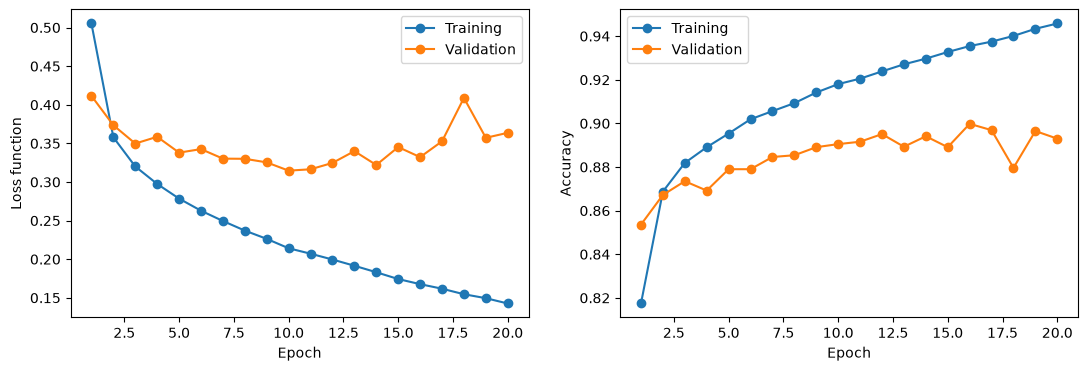

In [ ]:
plot_loss_accuracy()

We notice that the model starts to suffer from overfitting: performance on the validation set stagnates fairly quickly, while it keeps steadily improving on the training set.

The `validation_step()` and `test_step()` methods also allow calling the `validate()` and `test()` methods on `Trainer` instances respectively.

The `validate()` method computes the loss function and accuracy on the validation set (information we already have here since we compute these scores at the end of each epoch during training, but we illustrate its use anyway).

In [ ]:
trainer.validate(model, dataloader_val)

Validation: |                                                                                                 …

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃      Validate metric      ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       accuracy_val        │    0.8930000066757202     │
│         loss_val          │    0.3637053668498993     │
└───────────────────────────┴───────────────────────────┘

[{'loss_val': 0.3637053668498993, 'accuracy_val': 0.8930000066757202}]

Similarly, the `test()` method computes the loss function and accuracy on the test set.
However, we do not have a separate test set here, so we will see its use in other notebooks.
If we had a `dataloader_test` variable corresponding to the *dataloader* for the test set, the code would be as follows:
```python
trainer.test(model, dataloader_test)
```